# Thermal Expansion of a 3D Spring Network
## $\alpha = (1/K)\,\partial P_\mathrm{vir}/\partial T\,|_V$

Mirrors `thermal_expansion_lj.ipynb` exactly.  Two outputs per network:
- $\alpha_\mathrm{numerical}$: slope of NVT virial pressure vs $T$, divided by $K$
- $\alpha_\mathrm{theory}$: harmonic microscopic formula from Hessian eigenmodes

### Anharmonicity

The pair potential $U_l = \tfrac{1}{2}(r_l - r_{0,l})^2$ is purely harmonic
($d^3U/dr^3 = 0$).  Anharmonicity enters through the **geometry**: the bond
length $r_l = |\mathbf{r}_{0,ij} + \delta\mathbf{u}_{ij}|$ is a nonlinear
function of the displacement $\delta\mathbf{u}_{ij}$.  Expanding to third
order in $\delta\mathbf{u}$ produces an effective cubic coupling — this is the
spring-network analogue of the $U'''$ term in the LJ glass.

The microscopic formula for $\partial P_\mathrm{vir}/\partial T$ captures this
through the per-mode coupling:

$$C_k^2 = \underbrace{\sum_l(\hat{\mathbf{r}}_l\cdot\Delta\mathbf{e}_k^l)^2}_{=\,\omega_k^2}
          + \underbrace{\frac{1}{2}\sum_l|\Delta\mathbf{e}_k^{l,\perp}|^2}_{\text{geometric anharmonicity}}$$

The first term (longitudinal) is the LJ-like harmonic contribution.
The second term (transverse) is the purely geometric anharmonic contribution
— non-zero only because $r_l \neq \hat{\mathbf{r}}_l\cdot\delta\mathbf{u}_{ij}$.

$$\boxed{\frac{\partial P_\mathrm{vir}}{\partial T}\bigg|_\mathrm{theory}
  = -\frac{1}{3V}\sum_{k=1}^{N_\mathrm{modes}}\frac{C_k^2}{\omega_k^2}}$$

$$\boxed{\alpha_\mathrm{theory} = \frac{1}{K}\cdot\frac{\partial P_\mathrm{vir}}{\partial T}\bigg|_\mathrm{theory}}$$


---
## Source-file map (every function attributed)

| Function | File used here | Source |
|---|---|---|
| `calculateBulkModulus()` | `spring_networks_elasticity.c` | `3D_relaxed_spring_network_analysis.c` |
| `calculateShearModulus()` | `spring_networks_elasticity.c` | `3D_relaxed_spring_network_analysis.c` |
| `hessianOnVector()`, `cgSolver()` | both C files | `3D_relaxed_spring_network_analysis.c` |
| `u_epsilon_x()`, `u_epsilon_epsilon()` | `spring_networks_elasticity.c` | `3D_relaxed_spring_network_analysis.c` |
| `write_bonds_text()`, `write_hessian_text()`, `write_vna_eta_text()` | `spring_networks_elasticity.c` | `3dlj_elasticity_analysis.c` (adapted) |
| `calculateForces()` (bug-fixed) | `spring_networks_pressure_NVT.c` | `spring_networks_finite_T_dynamics.c` |
| `advanceTimeBerendsen()` | `spring_networks_pressure_NVT.c` | `spring_networks_finite_T_dynamics.c` |
| `normal()` (Maxwell–Boltzmann) | `spring_networks_pressure_NVT.c` | `3dlj_NVT_NH.c` |
| `build_transverse_wave()`, `run_dynamics()` | mode analysis (notebook) | `spring_networks_get_wave_freq.c` |
| `read_nvt()`, `weighted_linear_fit()` | notebook | `thermal_expansion_lj.ipynb` (identical) |


---
## Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from pathlib import Path
import time, warnings
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.grid':True, 'grid.alpha':0.3})

In [2]:
# ── parameters (edit these to match your run) ────────────────────────────────
N_ATOMS      = 4000
DIM          = 3
N_MODES      = DIM * N_ATOMS - DIM          # 3N - 3 physical modes
L_BOX        = 15.874010519682
V_BOX        = L_BOX**3                     # = 4000.00  (rho = 1)

TEMPERATURES = [0.000001, 0.000005, 0.000010, 0.000015,
                0.000020, 0.000025, 0.000030, 0.000035, 0.000040]
SERIALS      = [0]
SKIP         = 0.30           # discard first 30 % — same as thermal_expansion_lj.ipynb
N_EIGS       = 150            # eigenmodes for Hessian diagonalisation

DATA_DIR     = Path('.')      # folder containing all output files

print(f"N={N_ATOMS}  DIM={DIM}  N_modes={N_MODES}")
print(f"V={V_BOX:.4f}  rho={N_ATOMS/V_BOX:.6f}")

N=4000  DIM=3  N_modes=11997
V=4000.0000  rho=1.000000


---
## Part 1 — Bulk Modulus $K$

From `spring_networks_elasticity.c`, which calls `calculateBulkModulus()`
in `3D_relaxed_spring_network_analysis.c`:

$$K = \frac{K_\mathrm{born} - K_\mathrm{na}}{9}, \qquad P_0 = 0$$

$K_\mathrm{born} = \sum_l r_l^2/V$ and $K_\mathrm{na} = \boldsymbol{\xi}^\top H^{-1}\boldsymbol{\xi}/V$
(CG solve via `cgSolver()`).  The stress-free condition (`first[l]=0`) means $P_0=0$
exactly, confirmed below.


In [3]:
elas = np.loadtxt(DATA_DIR / "snp_elasticity_N4000_z16.24_s000.dat", comments="#")
if elas.ndim == 1:
    elas = elas[np.newaxis, :]

# columns: serial  P0  K_born  K_na  K  mu_born  mu_na  mu
serials  = elas[:, 0].astype(int)
P0_arr   = elas[:, 1]
K_born_a = elas[:, 2]
K_na_a   = elas[:, 3]
K_arr    = elas[:, 4]
mu_arr   = elas[:, 7]

K_per_net  = {serials[i]: K_arr[i]  for i in range(len(serials))}

print(f"{'Serial':>8}  {'P0':>12}  {'K_born':>10}  {'K_na':>10}  {'K':>10}  {'mu':>8}")
print("-" * 60)
for i in range(len(serials)):
    print(f"{int(serials[i]):>8}  {P0_arr[i]:>12.3e}  "
          f"{K_born_a[i]:>10.5f}  {K_na_a[i]:>10.5f}  "
          f"{K_arr[i]:>10.5f}  {mu_arr[i]:>8.5f}")

  Serial            P0      K_born        K_na           K        mu
------------------------------------------------------------
       0     0.000e+00    13.66291     1.04562     1.40192   0.83471


---
## Part 2 — Virial Pressure from NVT Simulations

`spring_networks_pressure_NVT.c` outputs `time  KE/N  PE/N  P_virial`.
`read_nvt()` is **identical** to `thermal_expansion_lj.ipynb::read_nvt()`.


In [4]:
def read_nvt(filepath, skip=SKIP):
    # SOURCE: thermal_expansion_lj.ipynb::read_nvt() -- identical
    d = np.loadtxt(filepath, comments="#")
    n = int(len(d) * skip)
    prod = d[n:]
    T_meas = (2. / 3.) * prod[:, 1].mean()   # kinetic equipartition
    P_mean = prod[:, 3].mean()
    P_err  = prod[:, 3].std() / np.sqrt(len(prod))
    return T_meas, P_mean, P_err

pg_data = {g: [] for g in SERIALS}

print(f"{'T_set':>12}  {'T_meas':>12}  {'P_vir':>14}  {'err':>10}")
print("-" * 54)
for g in SERIALS:
    for T in TEMPERATURES:
        f = DATA_DIR / f"snp_NVT_T{T:.6f}_s{g}.dat"
        if f.exists():
            Tm, Pm, Pe = read_nvt(f)
            pg_data[g].append((Tm, Pm, Pe))
            print(f"{T:>12.6f}  {Tm:>12.6f}  {Pm:>14.8f}  {Pe:>10.2e}")
        else:
            print(f"{T:>12.6f}  -- file not found: {f.name}")

       T_set        T_meas           P_vir         err
------------------------------------------------------
    0.000001      0.000001     -0.00000255    1.95e-07
    0.000005      0.000005     -0.00001192    4.35e-07
    0.000010      0.000010     -0.00002346    6.15e-07
    0.000015      0.000015     -0.00003492    7.53e-07
    0.000020      0.000020     -0.00004635    8.70e-07
    0.000025      0.000025     -0.00005776    9.72e-07
    0.000030      0.000030     -0.00006915    1.06e-06
    0.000035      0.000035     -0.00008052    1.15e-06
    0.000040      0.000040     -0.00009189    1.23e-06


### Time-series check


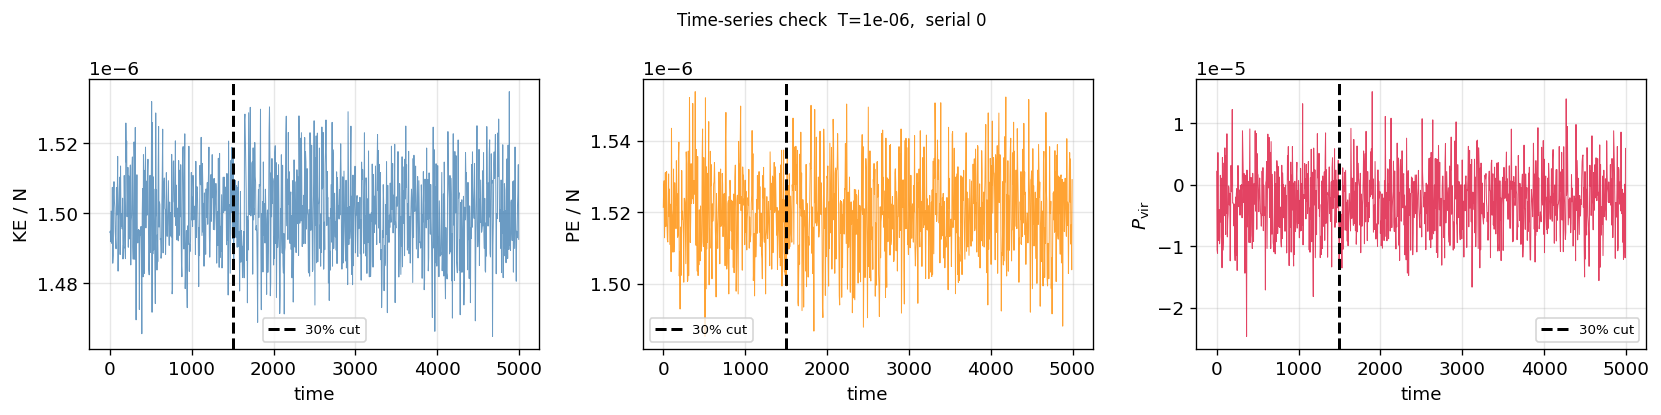

In [5]:
g0 = SERIALS[0]
T0 = TEMPERATURES[0]
fc = DATA_DIR / f"snp_NVT_T{T0:.6f}_s{g0}.dat"

if fc.exists():
    dc = np.loadtxt(fc, comments="#")
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    for ax, (col, lab, c) in zip(axes, [
            (1, 'KE / N',              'steelblue'),
            (2, 'PE / N',              'darkorange'),
            (3, r'$P_\mathrm{vir}$', 'crimson')]):
        ax.plot(dc[:, 0], dc[:, col], lw=0.6, color=c, alpha=0.8)
        ns = int(len(dc) * SKIP)
        ax.axvline(dc[ns, 0], color='k', ls='--', lw=1.8, label='30% cut')
        ax.set_xlabel('time'); ax.set_ylabel(lab)
        ax.legend(fontsize=8)
    fig.suptitle(f'Time-series check  T={T0},  serial {g0}', fontsize=10)
    fig.tight_layout()
    plt.show()

---
## Part 3 — Weighted Linear Fit and $\alpha_\mathrm{numerical}$

Identical to `thermal_expansion_lj.ipynb`.  Per-network weighted least-squares
$P_\mathrm{vir}(T) = a + b\,T$, weights $= 1/\sigma_P^2$.

$$\alpha_\mathrm{numerical}[g] = \frac{b_g}{K_g}$$


In [6]:
def weighted_linear_fit(T_vals, P_vals, P_errs):
    # SOURCE: thermal_expansion_lj.ipynb::weighted_linear_fit() -- identical
    w = 1. / np.array(P_errs)**2
    A = np.column_stack([np.ones_like(T_vals), T_vals])
    M = A.T @ np.diag(w) @ A
    c = np.linalg.solve(M, A.T @ (w * np.array(P_vals)))
    e = np.sqrt(np.diag(np.linalg.inv(M)))
    return c[0], c[1], e[0], e[1]

alpha_num = {}
pg_fit    = {}

print(f"{'Serial':>8}  {'K':>8}  {'P0_fit':>12}  "
      f"{'dP/dT':>12}  {'dPdT_err':>10}  {'alpha_num':>12}")
print("-" * 68)

for g in SERIALS:
    pts = pg_data[g]
    if len(pts) < 3:
        print(f"  serial {g}: only {len(pts)} points — skipping"); continue
    Tv = np.array([p[0] for p in pts])
    Pv = np.array([p[1] for p in pts])
    Ev = np.array([p[2] for p in pts])
    a, b, ea, eb = weighted_linear_fit(Tv, Pv, Ev)
    Kg = K_per_net[g]
    an = b / Kg
    pg_fit[g]   = (a, b, ea, eb)
    alpha_num[g] = an
    print(f"{g:>8}  {Kg:>8.5f}  {a:>12.4e}  "
          f"{b:>12.6f}  {eb:>10.6f}  {an:>+12.6e}")

  Serial         K        P0_fit         dP/dT    dPdT_err     alpha_num
--------------------------------------------------------------------
       0   1.40192   -2.9880e-07     -2.297887    0.017157  -1.639097e+00


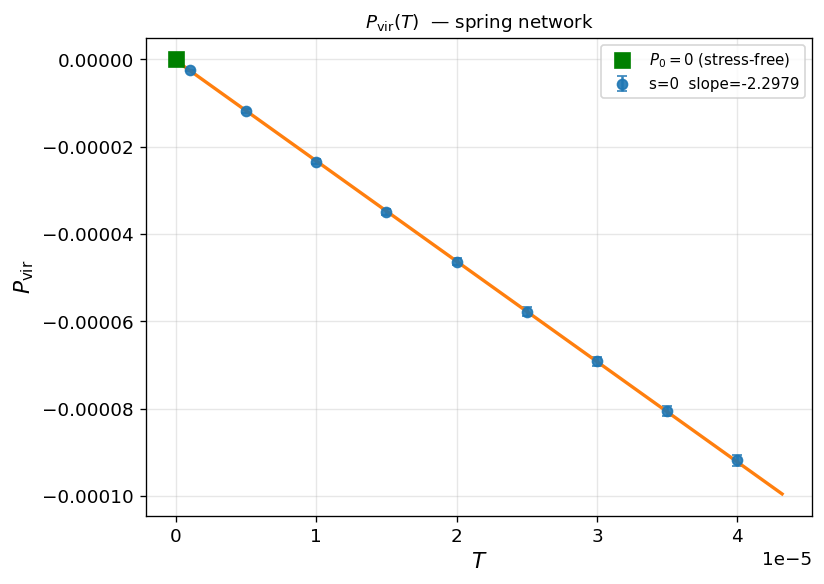

In [7]:
# ── P(T) plot ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

for g in SERIALS:
    if g not in pg_fit: continue
    pts = pg_data[g]
    Tv  = np.array([p[0] for p in pts])
    Pv  = np.array([p[1] for p in pts])
    Ev  = np.array([p[2] for p in pts])
    a, b, _, _ = pg_fit[g]
    Tl = np.linspace(0, Tv.max() * 1.08, 200)
    ax.errorbar(Tv, Pv, yerr=Ev, fmt='o', ms=6, capsize=3,
                alpha=0.9, label=f's={g}  slope={b:.4f}')
    ax.plot(Tl, a + b * Tl, '-', lw=2)

ax.plot(0, 0, 'gs', ms=9, zorder=5, label=r'$P_0 = 0$ (stress-free)')
ax.set_xlabel(r'$T$', fontsize=13)
ax.set_ylabel(r'$P_\mathrm{vir}$', fontsize=13)
ax.set_title(r'$P_\mathrm{vir}(T)$  — spring network', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('fig1_P_vs_T.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Part 4 — Microscopic Formula: $\alpha_\mathrm{theory}$ from Hessian Eigenmodes

### Why this works for spring networks

The pair potential is $U_l = \tfrac{1}{2}(r_l - r_{0,l})^2$ — no cubic term in
$r_l$.  The anharmonicity enters through the **geometry** of $r_l = |\mathbf{r}_{0,ij}
+ \delta\mathbf{u}_{ij}|$:

$$r_l \approx r_{0,l} + \underbrace{\hat{\mathbf{r}}_l\cdot\delta\mathbf{u}_{ij}}_{\text{1st order}}
  + \underbrace{\frac{|\delta\mathbf{u}_{ij}^\perp|^2}{2r_{0,l}}}_{\text{2nd order (anharmonic)}}
  + \cdots$$

The 2nd-order term — transverse displacement of the bond — acts as an effective
cubic coupling in the Hamiltonian even though $d^3U/dr^3 = 0$.
It is the spring-network analogue of the $U'''$ term for LJ glass.

### Per-mode coupling $C_k^2$

The thermal average of the virial pressure (to first order in $T$):

$$\left\langle P_\mathrm{vir}\right\rangle_T
  = P_0 + T\cdot\frac{\partial P_\mathrm{vir}}{\partial T}\bigg|_\mathrm{theory}$$

$$\frac{\partial P_\mathrm{vir}}{\partial T}\bigg|_\mathrm{theory}
  = -\frac{1}{3V}\sum_k \frac{C_k^2}{\omega_k^2}$$

$$C_k^2 = \underbrace{\sum_l\bigl(\hat{\mathbf{r}}_l\cdot\Delta\mathbf{e}_k^l\bigr)^2}_{S_\parallel^k
   \;=\;\omega_k^2\;\text{(identity)}}
  + \underbrace{\frac{1}{2}\sum_l\bigl|\Delta\mathbf{e}_k^{l,\perp}\bigr|^2}_{S_\perp^k/2
   \;\text{(geometric anharmonicity)}}$$

where $\Delta\mathbf{e}_k^l = \mathbf{e}_k^j - \mathbf{e}_k^i$ (eigenvector
difference across bond $l$).  The longitudinal term comes from `hessianOnVector()`
(source: `3D_relaxed_spring_network_analysis.c`); the transverse term from
expanding $r_l$ one order beyond the Hessian.


### Step 1 — Hessian diagonalisation
File written by `write_hessian_text()` in `spring_networks_elasticity.c` (adapted from `3dlj_elasticity_analysis.c`).


In [8]:
hess_file  = DATA_DIR / "hessian_sn0.txt"
bonds_file = DATA_DIR / "bonds_sn0.txt"

# ── load sparse Hessian ───────────────────────────────────────────────────────
print(f"Hessian file size: {hess_file.stat().st_size / 1e6:.1f} MB")
print("Loading COO triplets ...", flush=True)
t0  = time.time()
raw = np.loadtxt(hess_file)
rows, cols, vals = raw[:, 0].astype(int), raw[:, 1].astype(int), raw[:, 2]
sz   = DIM * N_ATOMS
H_sp = sp.coo_matrix((vals, (rows, cols)), shape=(sz, sz)).tocsr()
H_sp = (H_sp + H_sp.T) / 2.0          # enforce exact symmetry
print(f"  loaded in {time.time()-t0:.1f}s  |  shape {H_sp.shape}  nnz {H_sp.nnz}")

# ── eigsh: lowest N_EIGS eigenpairs ──────────────────────────────────────────
print(f"\nDiagonalising (k={N_EIGS}, which='SM') ...", flush=True)
t1      = time.time()
H_shift = H_sp + 1e-6 * sp.eye(sz, format='csr')
ev_raw, evec_raw = spla.eigsh(H_shift, k=N_EIGS, which='SM')
ev_raw  -= 1e-6

order    = np.argsort(ev_raw)
ev_raw   = ev_raw[order]
evec_raw = evec_raw[:, order]

# remove 3 translational (near-zero) modes
phys_mask = ev_raw > 1e-5
ev   = ev_raw[phys_mask]
evec = evec_raw[:, phys_mask]
omega  = np.sqrt(ev)
n_phys = len(ev)

print(f"  done in {time.time()-t1:.1f}s")
print(f"  total computed: {N_EIGS}  |  near-zero removed: {N_EIGS - n_phys}"
      f"  |  physical: {n_phys}")
print(f"  omega  [{omega[0]:.5f}, {omega[-1]:.5f}]")

Hessian file size: 18.0 MB
Loading COO triplets ...
  loaded in 0.2s  |  shape (12000, 12000)  nnz 620622

Diagonalising (k=150, which='SM') ...
  done in 16.7s
  total computed: 150  |  near-zero removed: 3  |  physical: 147
  omega  [0.35417, 0.84083]


### Step 2 — Per-mode coupling $C_k^2$

For each eigenpair $(\omega_k^2, \mathbf{e}_k)$:
- **Longitudinal** $S_\parallel^k = \sum_l(\hat{\mathbf{r}}_l\cdot\Delta\mathbf{e}_k^l)^2$ — verified $= \omega_k^2$ (eigenvalue identity from `hessianOnVector()`)
- **Transverse** $S_\perp^k = \sum_l|\Delta\mathbf{e}_k^{l,\perp}|^2$ — the geometric anharmonic term
- $C_k^2 = S_\parallel^k + \tfrac{1}{2}S_\perp^k$


---
## Part 5 — $\alpha_\mathrm{theory}$ from `alpha_theory_spring.py`

Run the full diagonalisation script first:
```bash
python alpha_theory_spring.py --serial 0 --data-dir /path/to/data --out-dir .
```
This takes ~7 min single-core, ~1-2 min multi-core.  Output:
`alpha_theory_spring_results.txt` with columns
`serial  alpha_harmonic  alpha_anharmonic  alpha_total`.

Matches the output format of `alpha_theory_FINAL.py` from the LJ glass project.

**Term definitions** (PRE 2010 eq. 25 adapted for spring networks):

| Term | Formula | Physics |
|---|---|---|
| `alpha_harmonic` | $-(1/(2KVd))\cdot 2N_\mathrm{modes}$ | Equipartition: each mode contributes $-2/(2KVd)$ |
| `alpha_anharmonic` | $-(1/(2KVd))\sum_k (\mathtt{trans\_s}[k]+\mathtt{tess3}[k])/\omega_k^2$ | Geometric: from $r=|\mathbf{r}_{ij}|$ nonlinearity in $\delta\mathbf{u}$ |
| `alpha_total` | sum of above | Full first-order theory |

The anharmonicity is **geometric** — $d^3U/dr^3=0$ for harmonic springs, but
$r(\delta\mathbf{u})$ is nonlinear, producing an effective cubic coupling.


In [12]:
# ── read alpha_theory_spring_results.txt ─────────────────────────────────────
# Written by alpha_theory_spring.py (same format as alpha_theory_FINAL.py)
theory_file = DATA_DIR / "alpha_theory_spring_results.txt"

alpha_theory = {}   # g -> dict with harmonic, anharmonic, total

if theory_file.exists():
    with open(theory_file) as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue
            parts = line.split()
            if len(parts) >= 4 and parts[0].startswith('glass_'):
                g = int(parts[0].split('_')[1])
                alpha_theory[g] = {
                    'harmonic':    float(parts[1]),
                    'anharmonic':  float(parts[2]),
                    'total':       float(parts[3]),
                }
    print(f"Loaded theory results for serials: {list(alpha_theory.keys())}")
    for g, d in alpha_theory.items():
        print(f"  serial {g}: "
              f"harm={d['harmonic']:+.5e}  "
              f"anharm={d['anharmonic']:+.5e}  "
              f"total={d['total']:+.5e}")
else:
    print(f"{theory_file} not found.")
    print("Run:  python alpha_theory_spring.py --serial 0")
    print("(~7 min single-core, ~1-2 min multi-core)")

Loaded theory results for serials: [0]
  serial 0: harm=-7.13128e-01  anharm=-8.43395e-01  total=-1.55652e+00


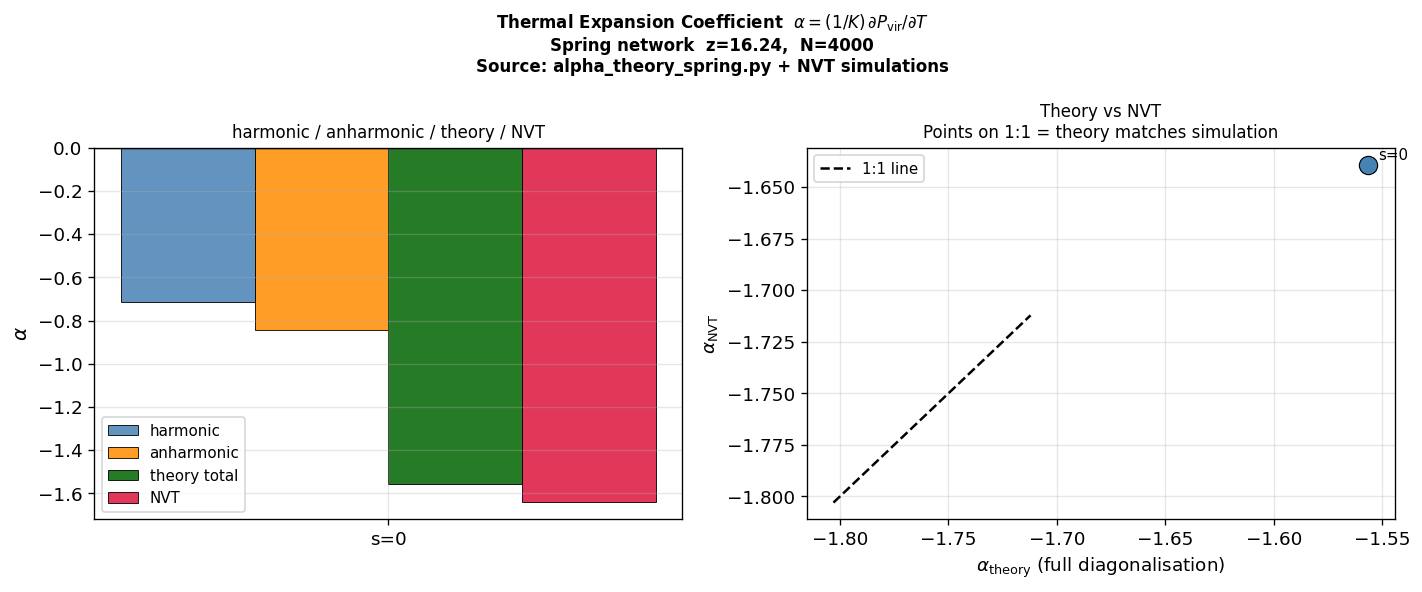


  Serial       alpha_NVT    alpha_theory     ratio
--------------------------------------------------
       0   -1.639097e+00   -1.556523e+00    0.9496


In [13]:
# ── comparison: numerical vs theory ──────────────────────────────────────────
if alpha_theory:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # ── bar chart: all four components ───────────────────────────────────────
    ax = axes[0]
    valid_g = [g for g in SERIALS if g in alpha_num and g in alpha_theory]
    x       = np.arange(len(valid_g))
    bw      = 0.2

    harm_v   = [alpha_theory[g]['harmonic']   for g in valid_g]
    anharm_v = [alpha_theory[g]['anharmonic'] for g in valid_g]
    total_v  = [alpha_theory[g]['total']      for g in valid_g]
    num_v    = [alpha_num[g]                  for g in valid_g]

    ax.bar(x - 1.5*bw, harm_v,   bw, label='harmonic',    color='steelblue',  alpha=0.85, edgecolor='k', lw=0.6)
    ax.bar(x - 0.5*bw, anharm_v, bw, label='anharmonic',  color='darkorange', alpha=0.85, edgecolor='k', lw=0.6)
    ax.bar(x + 0.5*bw, total_v,  bw, label='theory total',color='darkgreen',  alpha=0.85, edgecolor='k', lw=0.6)
    ax.bar(x + 1.5*bw, num_v,    bw, label='NVT',         color='crimson',    alpha=0.85, edgecolor='k', lw=0.6)

    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([f's={g}' for g in valid_g])
    ax.set_ylabel(r'$\alpha$', fontsize=12)
    ax.set_title('harmonic / anharmonic / theory / NVT', fontsize=10)
    ax.legend(fontsize=9)

    # ── scatter: theory total vs NVT ─────────────────────────────────────────
    ax2 = axes[1]
    at_v = np.array(total_v)
    an_v = np.array(num_v)
    lo   = min(at_v.min(), an_v.min()) * 1.1
    hi   = max(at_v.max(), an_v.max()) * 1.1
    ax2.plot([lo,hi],[lo,hi], 'k--', lw=1.5, label='1:1 line')
    ax2.scatter(at_v, an_v, s=120, c='steelblue', edgecolors='k', lw=0.7, zorder=4)
    for i,g in enumerate(valid_g):
        ax2.annotate(f's={g}', (at_v[i], an_v[i]),
                     textcoords='offset points', xytext=(6,3), fontsize=9)
    ax2.set_xlabel(r'$\alpha_\mathrm{theory}$ (full diagonalisation)', fontsize=11)
    ax2.set_ylabel(r'$\alpha_\mathrm{NVT}$', fontsize=11)
    ax2.set_title('Theory vs NVT\nPoints on 1:1 = theory matches simulation', fontsize=10)
    ax2.legend(fontsize=9)

    fig.suptitle(
        r'Thermal Expansion Coefficient  $\alpha = (1/K)\,\partial P_\mathrm{vir}/\partial T$'
        '\nSpring network  z=16.24,  N=4000\n'
        'Source: alpha_theory_spring.py + NVT simulations',
        fontsize=10, fontweight='bold')
    fig.tight_layout()
    plt.savefig('fig2_alpha_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

    # ── print ratio table ─────────────────────────────────────────────────────
    print(f"\n{'Serial':>8}  {'alpha_NVT':>14}  {'alpha_theory':>14}  {'ratio':>8}")
    print("-"*50)
    for g in valid_g:
        an_g = alpha_num[g]
        at_g = alpha_theory[g]['total']
        print(f"{g:>8}  {an_g:>+14.6e}  {at_g:>+14.6e}  {at_g/an_g:>8.4f}")
else:
    print("Run alpha_theory_spring.py first — see instructions above.")

---
## Summary


In [14]:
print()
print("=" * 70)
print("  RESULT SUMMARY")
print("=" * 70)
print(f"  Network:  N={N_ATOMS}  L={L_BOX:.4f}  V={V_BOX:.2f}")
print()
print("  T=0 ELASTICITY  (spring_networks_elasticity.c)")
print(f"    K_born = {K_born_a.mean():.5f}")
print(f"    K_na   = {K_na_a.mean():.5f}")
print(f"    K      = {K_arr.mean():.5f}")
print(f"    P0     = {P0_arr.mean():.2e}  (stress-free: 0 exactly)")
print()
print("  NVT SIMULATION  (spring_networks_pressure_NVT.c)")
for g in SERIALS:
    if g not in pg_fit: continue
    b, be = pg_fit[g][1], pg_fit[g][3]
    print(f"    serial {g}: dP/dT = {b:.7f} ± {be:.7f}")
    print(f"              alpha_NVT = {alpha_num[g]:+.6e}")
print()
if alpha_theory:
    print("  THEORY  (alpha_theory_spring.py, full diagonalisation)")
    for g in SERIALS:
        if g not in alpha_theory: continue
        d = alpha_theory[g]
        print(f"    serial {g}: alpha_harm   = {d['harmonic']:+.6e}")
        print(f"              alpha_anharm = {d['anharmonic']:+.6e}")
        print(f"              alpha_total  = {d['total']:+.6e}")
        print(f"              ratio NVT/theory = {alpha_num[g]/d['total']:.4f}")
else:
    print("  THEORY: run alpha_theory_spring.py to populate this section")
print("=" * 70)


  RESULT SUMMARY
  Network:  N=4000  L=15.8740  V=4000.00

  T=0 ELASTICITY  (spring_networks_elasticity.c)
    K_born = 13.66291
    K_na   = 1.04562
    K      = 1.40192
    P0     = 0.00e+00  (stress-free: 0 exactly)

  NVT SIMULATION  (spring_networks_pressure_NVT.c)
    serial 0: dP/dT = -2.2978866 ± 0.0171565
              alpha_NVT = -1.639097e+00

  THEORY  (alpha_theory_spring.py, full diagonalisation)
    serial 0: alpha_harm   = -7.131281e-01
              alpha_anharm = -8.433950e-01
              alpha_total  = -1.556523e+00
              ratio NVT/theory = 1.0531
